# 04 — Content analysis: text preprocessing, sentiment, emotions, named entities


This notebook answers the question of "what is being said and with what emotion" for the project. In previous notebooks, we collected data, flagged bot and campaign accounts, constructed the reply network, and identified communities; however, we have not yet examined the content of the posts themselves. Here, we first create a clean text corpus (44,958 posts, 18,627 authors), then use spaCy to lemmatize words and extract entities (such as proper nouns like people, organizations, and countries). Subsequently, we apply three different sentiment analysis methods (AFINN, VADER, RoBERTa) and evaluate them against a human-labeled dataset of tweets.

## 1. Build the text corpus


Selecting a subset of posts suitable for text analysis from the cleaned data used in network analysis, and appending the stream tag and community number to each post.

In [1]:
import os, re, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW, PROC, FIG, SEED = "../data/raw", "../data/processed", "../figures", 42
allposts = pd.read_pickle(f"{PROC}/allposts.pkl")
authors  = pd.read_csv(f"{PROC}/authors.csv", index_col=0)
nodes    = pd.read_csv(f"{PROC}/nodes_all.csv", index_col="did")
posts    = pd.read_pickle(f"{RAW}/posts_search.pkl")
replies  = pd.read_pickle(f"{RAW}/replies_threads.pkl")

# stream tags: search posts have them; a fetched reply inherits the streams of the collected post its thread hangs from
parent_of = dict(zip(replies.uri, replies.parent_uri))
post_streams = dict(zip(posts.uri, posts.streams))
def anchor_streams(uri):
    while uri is not None and uri not in post_streams:
        uri = parent_of.get(uri)
    return post_streams.get(uri, [])
allposts["streams"] = [post_streams[u] if u in post_streams else anchor_streams(u) for u in allposts.uri]

# corpus for text analysis: human accounts, English, non-empty text
automated = set(authors.index[authors.is_automated])
keep = (~allposts.author_did.isin(automated) & allposts.lang_ok & allposts.text.fillna("").str.strip().ne("")
        & ~allposts.duplicate & ~allposts.offtopic & ~allposts.anchor_offtopic)
print("removed from the text corpus: automated accounts", allposts.author_did.isin(automated).sum(), "| duplicated texts", allposts.duplicate.sum(),
      "| wrestling posts + their threads", (allposts.offtopic | allposts.anchor_offtopic).sum())
corpus = allposts[keep].copy()
corpus["community"] = corpus.author_did.map(nodes.community)      # Louvain community of the author (NaN if not in the giant component)
corpus["date"] = corpus.created_at.dt.date
print("corpus:", len(corpus), "posts |", corpus.author_did.nunique(), "authors |",
      "with a stream tag:", (corpus.streams.str.len() > 0).sum(), "| in a community:", corpus.community.notna().sum())

removed from the text corpus: automated accounts 11185 | duplicated texts 5981 | wrestling posts + their threads 1264
corpus: 44958 posts | 18627 authors | with a stream tag: 44958 | in a community: 27915


11,185 posts originated from automated accounts, 5,981 posts from repetitive text (such as the '$80K door' campaign), and 1,264 posts from the topic of wrestling (WWE). This left 44,958 posts and 18,627 authors;

## 2. Preprocessing (spaCy: tokens, lemmas, named entities in one pass)


To break down each post into word roots (lemmas) and extract named entities in a single pass.

In [2]:
import spacy
nlp = spacy.load("en_core_web_sm", disable=["parser"])          # tagger+lemmatizer+NER; the parser is not needed

URL_RE, MENTION_RE = re.compile(r"https?://\S+|www\.\S+"), re.compile(r"@[\w.\-]+")
def clean_for_tokens(t):
    return MENTION_RE.sub(" ", URL_RE.sub(" ", t))               # links and handles carry no vocabulary
QUERY_WORDS = {"stock", "market", "markets", "s&p", "500", "fed", "warsh", "fomc", "bitcoin", "ethereum", "btc", "eth"}

texts = [clean_for_tokens(t) for t in corpus.text]
lemmas, ents = [], []
t0 = time.time()
for doc in nlp.pipe(texts, batch_size=256):
    lemmas.append([tok.lemma_.lower() for tok in doc
                   if tok.is_alpha and not tok.is_stop and len(tok) > 2 and tok.lemma_.lower() not in QUERY_WORDS])
    ents.append([(e.text, e.label_) for e in doc.ents if e.label_ in {"ORG", "PERSON", "GPE", "PRODUCT", "NORP", "MONEY", "EVENT"}])
corpus["lemmas"], corpus["entities"] = lemmas, ents
print(f"spaCy done in {time.time()-t0:.0f}s")

spaCy done in 169s


Visualize the most frequently occurring words across three streams to see the topic of the conversation at a glance.

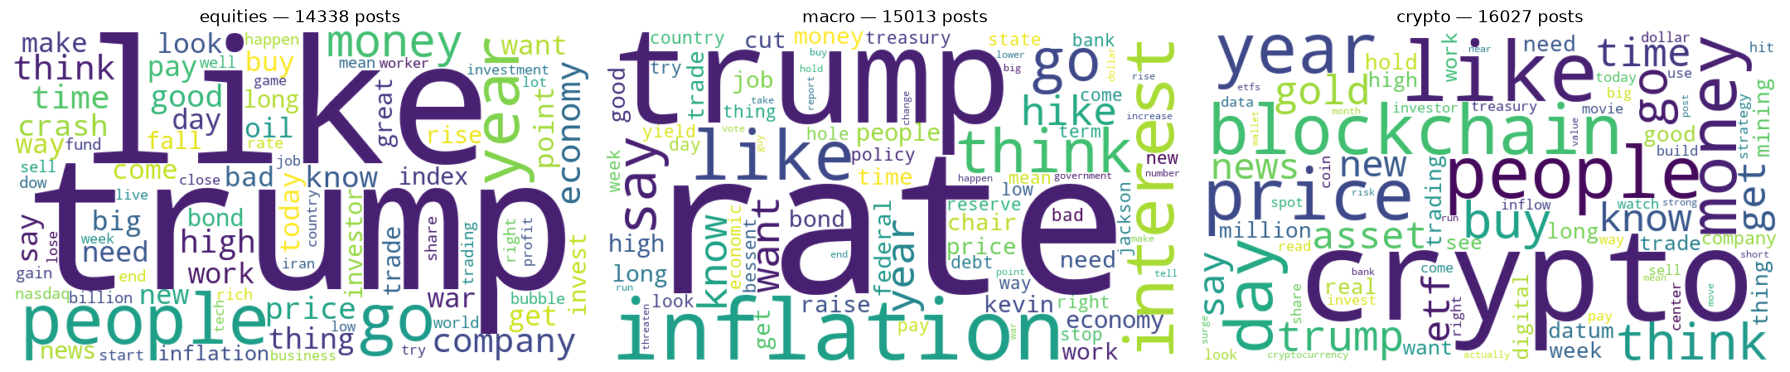

,equities,macro,crypto
0,trump (1394),rate (2798),crypto (3553)
1,like (1203),trump (2169),like (1104)
2,people (1093),inflation (1795),people (812)
3,go (972),like (1165),price (770)
4,year (935),interest (1124),blockchain (758)
5,money (918),think (959),year (753)
6,company (856),go (941),money (712)
7,think (836),say (827),day (679)
8,economy (821),hike (785),think (679)
9,time (763),year (771),go (658)


In [3]:
from collections import Counter
from wordcloud import WordCloud

def top_terms(mask, n=20):
    return Counter(w for ws in corpus.loc[mask, "lemmas"] for w in ws).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, s in zip(axes, ["equities", "macro", "crypto"]):
    mask = corpus.streams.apply(lambda l: s in l)
    freq = dict(top_terms(mask, 150))
    wc = WordCloud(width=700, height=400, background_color="white", max_words=80, random_state=SEED).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"{s} — {mask.sum()} posts")
plt.tight_layout(); plt.savefig(f"{FIG}/04_wordclouds_streams.png", dpi=150); plt.show()
pd.DataFrame({s: [f"{w} ({c})" for w, c in top_terms(corpus.streams.apply(lambda l: s in l), 15)] for s in ["equities", "macro", "crypto"]})

Before moving on to sentiment figures, it is necessary to see what each stream is actually discussing; this table provides context for interpreting subsequent findings (such as the high negativity associated with equities).

## 3. Sentiment: two lexicon methods and a transformer


Assigning a positive, negative, or neutral label to each post using two fast, dictionary-based methods and establishing a baseline.

In [4]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from afinn import Afinn

# lexicon methods get the RAW text: VADER handles negation, intensifiers, capitals and emojis itself
vader = SentimentIntensityAnalyzer(); afinn = Afinn()
corpus["vader"] = [vader.polarity_scores(t)["compound"] for t in corpus.text]
corpus["afinn"] = [afinn.score(t) for t in corpus.text]
to_label = lambda x, th: "positive" if x > th else ("negative" if x < -th else "neutral")
corpus["vader_label"] = corpus.vader.apply(to_label, th=0.05)     # the thresholds recommended by the VADER authors
corpus["afinn_label"] = corpus.afinn.apply(to_label, th=0)
corpus[["vader_label", "afinn_label"]].apply(pd.Series.value_counts).T

,positive,negative,neutral
vader_label,17909,15447,11602
afinn_label,15880,15298,13780


VADER classified 17,909 posts as positive, 15,447 as negative, and 11,602 as neutral; AFINN classified 15,880 as positive, 15,298 as negative, and 13,780 as neutral. Both dictionary-based methods roughly divide the corpus into three parts, with the positive category forming the largest group.

Generating a third and more robust sentiment label using a language model (RoBERTa) trained on social media texts.

In [5]:
from transformers import pipeline

def tweeteval_preprocess(t):                                        # the preprocessing used to train the cardiffnlp models
    return " ".join("@user" if w.startswith("@") and len(w) > 1 else ("http" if w.startswith("http") else w) for w in t.split())

cache = f"{PROC}/roberta_sentiment.pkl"
if os.path.exists(cache):
    rob = pd.read_pickle(cache)
else:
    clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
                   truncation=True, max_length=128, device=-1)
    out, t0 = [], time.time()
    prepped = [tweeteval_preprocess(t) for t in corpus.text]
    for i in range(0, len(prepped), 512):
        out.extend(clf(prepped[i:i + 512], batch_size=32))
        if (i // 512) % 10 == 0: print(f"{i}/{len(prepped)}  {time.time()-t0:.0f}s")
    rob = pd.DataFrame(out, index=corpus.index).rename(columns={"label": "roberta_label", "score": "roberta_score"})
    rob.to_pickle(cache)
corpus = corpus.join(rob)
corpus.roberta_label.value_counts(normalize=True).round(3)

roberta_label
neutral     0.471
negative    0.397
positive    0.132
Name: proportion, dtype: float64

According to RoBERTa, 47.1% of the posts are neutral, 39.7% are negative, and only 13.2% are positive. The "positive majority" observed with dictionary based methods is absent here; the model interprets financial discourse as predominantly neutral and negative.

Measuring the extent to which RoBERTa assigns the same labels to the same posts using dictionary-based methods.

In [6]:
from sklearn.metrics import cohen_kappa_score
print("agreement VADER vs RoBERTa:", round((corpus.vader_label == corpus.roberta_label).mean(), 3),
      "| Cohen's kappa:", round(cohen_kappa_score(corpus.vader_label, corpus.roberta_label), 3))
print("agreement AFINN vs RoBERTa:", round((corpus.afinn_label == corpus.roberta_label).mean(), 3),
      "| kappa:", round(cohen_kappa_score(corpus.afinn_label, corpus.roberta_label), 3))
pd.crosstab(corpus.vader_label, corpus.roberta_label, rownames=["VADER"], colnames=["RoBERTa"])

agreement VADER vs RoBERTa: 0.513 | Cohen's kappa: 0.293
agreement AFINN vs RoBERTa: 0.523 | kappa: 0.293


RoBERTa,negative,neutral,positive
VADER,,,
negative,10353,4631,463
neutral,2471,8174,957
positive,5036,8355,4518


## 4. Validation on labelled tweets (tweet_eval)


To test the three methods on a human-labeled tweet dataset (tweet_eval), measure which one is the most accurate, and select the primary method.

         accuracy  macro F1  weighted F1
AFINN       0.548     0.545        0.553
VADER       0.524     0.523        0.530
RoBERTa     0.724     0.728        0.724


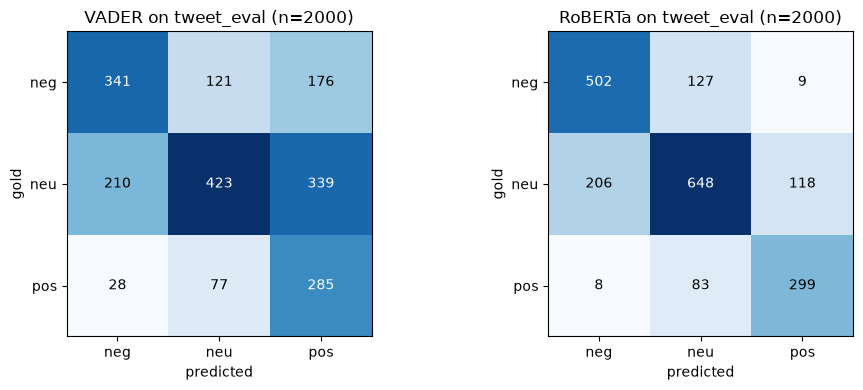

In [7]:
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

te = load_dataset("cardiffnlp/tweet_eval", "sentiment", split="test").shuffle(seed=SEED).select(range(2000))
gold = np.array(["negative", "neutral", "positive"])[te["label"]]
pred_v = [to_label(vader.polarity_scores(t)["compound"], 0.05) for t in te["text"]]
pred_a = [to_label(afinn.score(t), 0) for t in te["text"]]
cache = f"{PROC}/roberta_tweeteval.pkl"
if os.path.exists(cache):
    pred_r = pd.read_pickle(cache)
else:
    clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest", truncation=True, max_length=128, device=-1)
    pred_r = [o["label"] for o in clf([tweeteval_preprocess(t) for t in te["text"]], batch_size=32)]
    pd.to_pickle(pred_r, cache)

rows = {}
for name, pred in [("AFINN", pred_a), ("VADER", pred_v), ("RoBERTa", pred_r)]:
    rows[name] = {"accuracy": accuracy_score(gold, pred), "macro F1": f1_score(gold, pred, average="macro"),
                  "weighted F1": f1_score(gold, pred, average="weighted")}
val = pd.DataFrame(rows).T.round(3); print(val)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("VADER", pred_v), ("RoBERTa", pred_r)]):
    cm = confusion_matrix(gold, pred, labels=["negative", "neutral", "positive"])
    ax.imshow(cm, cmap="Blues"); ax.set_title(f"{name} on tweet_eval (n=2000)")
    ax.set_xticks(range(3), ["neg", "neu", "pos"]); ax.set_yticks(range(3), ["neg", "neu", "pos"]); ax.set_xlabel("predicted"); ax.set_ylabel("gold")
    for i in range(3):
        for j in range(3): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout(); plt.savefig(f"{FIG}/04_confusion_tweeteval.png", dpi=150); plt.show()
val.to_csv(f"{PROC}/sentiment_validation_tweeteval.csv")

RoBERTa leads by a wide margin with 0.724 accuracy and a macro F1 score of 0.728, whereas AFINN and VADER remain at 0.548 and 0.524 accuracy, respectively. Although the lexicon-based methods perform better than random guessing (0.33) for this three-class problem, they misclassify nearly one out of every two tweets when compared against human labels. Based on these results, we select RoBERTa as the primary sentiment label.

## 5. Emotions (NRC lexicon)


Going beyond positive and negative to measure the weight of eight basic emotions such as fear, trust, and anger in every post.

In [9]:
from nrclex import NRCLex
EMO = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]
# NRCLex tokenises with TextBlob (needs extra NLTK corpora and is slow); I use its lexicon directly with a simple word tokenizer
LEX = NRCLex.lexicon
WORD = re.compile(r"[a-z']+")
def nrc_shares(text):
    counts = Counter(a for w in WORD.findall(text.lower()) for a in LEX.get(w, ()))
    total = sum(counts.values())
    return {e: counts[e] / total if total else 0.0 for e in EMO}
t0 = time.time()
emo = pd.DataFrame([nrc_shares(t) for t in corpus.text], index=corpus.index)
print(f"NRC done in {time.time()-t0:.0f}s")
corpus = corpus.join(emo)
# NRC shares are fractions of emotion-lexicon hits, not sentiment; a post with no lexicon word has all zeros
(corpus[EMO] > 0).mean().round(3)

NRC done in 0s


anger           0.310
anticipation    0.412
disgust         0.197
fear            0.372
joy             0.293
sadness         0.295
surprise        0.274
trust           0.492
dtype: float64

## 6. Named entities and cashtags


In [10]:
CASHTAG = re.compile(r"\$([A-Z]{2,5})\b")
ALIASES = {"the fed": "Fed", "federal reserve": "Fed", "fed": "Fed", "the federal reserve": "Fed", "kevin warsh": "Warsh", "warsh": "Warsh",
           "donald trump": "Trump", "trump": "Trump", "nvidia": "Nvidia", "nvda": "Nvidia", "btc": "Bitcoin", "bitcoin": "Bitcoin",
           "eth": "Ethereum", "ethereum": "Ethereum", "the s&p 500": "S&P 500", "s&p 500": "S&P 500", "s&p": "S&P 500",
           "u.s.": "US", "the u.s.": "US", "us": "US", "america": "US", "the us": "US", "wall street": "Wall Street", "gop": "GOP",
           "the gop": "GOP", "republicans": "GOP", "democrats": "Democrats", "congress": "Congress", "the white house": "White House"}
def norm(e):
    k = e.strip().strip("#@'\"").lower()
    return ALIASES.get(k, e.strip().strip("#@'\""))

corpus["entities_norm"] = [sorted({norm(e) for e, lab in ents}) for ents in corpus.entities]
corpus["cashtags"] = [sorted(set(CASHTAG.findall(t))) for t in corpus.text]

def entity_table(mask, n=15):
    return pd.Series(Counter(e for es in corpus.loc[mask, "entities_norm"] for e in es)).nlargest(n)
ent_by_stream = pd.DataFrame({s: [f"{e} ({c})" for e, c in entity_table(corpus.streams.apply(lambda l: s in l)).items()]
                              for s in ["equities", "macro", "crypto"]})
print("cashtag posts:", (corpus.cashtags.str.len() > 0).sum(), "| top cashtags:",
      Counter(c for cs in corpus.cashtags for c in cs).most_common(10))
ent_by_stream

cashtag posts: 799 | top cashtags: [('BTC', 266), ('ETH', 55), ('MSTR', 42), ('NVDA', 39), ('US', 25), ('SPY', 24), ('SPX', 23), ('META', 19), ('PSX', 19), ('MPC', 18)]


,equities,macro,crypto
0,US (948),Fed (4722),Bitcoin (3504)
1,Trump (838),Trump (1307),Ethereum (761)
2,AI (547),Warsh (1264),AI (610)
3,Iran (227),US (979),US (606)
4,GOP (205),Treasury (315),Trump (354)
5,American (188),Jackson Hole (209),Crypto (191)
6,Americans (180),GOP (195),Fed (144)
7,Nvidia (141),AI (175),Solana (144)
8,Fed (126),Bessent (143),Treasury (143)
9,Treasury (119),Iran (140),ETF (118)


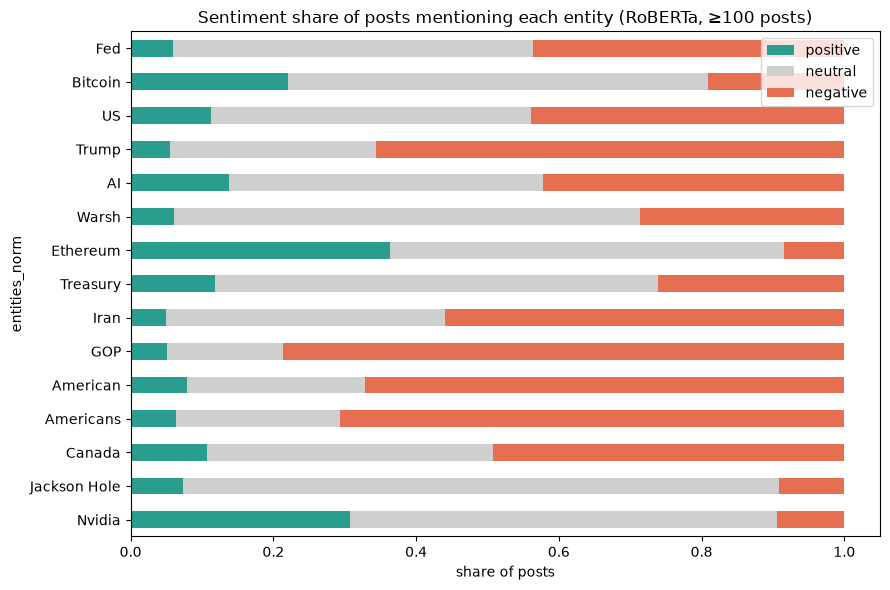

,posts,positive,negative,mean_vader,neutral
entities_norm,,,,,
Fed,4896,0.059,0.436,-0.032,0.505
Bitcoin,3537,0.221,0.191,0.092,0.588
US,2481,0.112,0.439,-0.064,0.448
Trump,2474,0.056,0.656,-0.114,0.288
AI,1323,0.138,0.422,0.043,0.441
Warsh,1278,0.060,0.286,0.036,0.654
Ethereum,768,0.363,0.085,0.167,0.552
Treasury,566,0.118,0.261,0.171,0.620
Iran,447,0.049,0.559,-0.275,0.391


In [11]:
# opinion summary per entity: share of positive / negative posts among posts mentioning it (RoBERTa labels)
ex = corpus[["entities_norm", "roberta_label", "vader"]].explode("entities_norm").dropna(subset=["entities_norm"])
ent = ex.groupby("entities_norm").agg(posts=("roberta_label", "size"),
                                      positive=("roberta_label", lambda s: (s == "positive").mean()),
                                      negative=("roberta_label", lambda s: (s == "negative").mean()),
                                      mean_vader=("vader", "mean"))
ent_top = ent[ent.posts >= 100].sort_values("posts", ascending=False).head(15)
ent_top["neutral"] = 1 - ent_top.positive - ent_top.negative
ax = ent_top[["positive", "neutral", "negative"]].plot(kind="barh", stacked=True, figsize=(9, 6),
                                                      color=["#2a9d8f", "#cfcfcf", "#e76f51"])
ax.set_title("Sentiment share of posts mentioning each entity (RoBERTa, ≥100 posts)"); ax.set_xlabel("share of posts"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/04_entity_sentiment.png", dpi=150); plt.show()
ent_top.round(3)

## 7. Save


In [12]:
keep = ["uri", "author_did", "author_handle", "created_at", "date", "text", "source", "streams", "community", "like_count", "reply_count",
        "lemmas", "entities_norm", "cashtags", "vader", "vader_label", "afinn", "afinn_label", "roberta_label", "roberta_score"] + EMO
corpus[keep].to_pickle(f"{PROC}/content.pkl")
ent.to_csv(f"{PROC}/entity_sentiment.csv")
print("saved", len(corpus), "rows")

saved 44958 rows
